# 02 · Exploratory Data Analysis (EDA)

Tujuan EDA di proyek sistem rekomendasi bukan sekadar membuat grafik, tetapi menjawab pertanyaan yang **menentukan desain model**:

1. Seperti apa distribusi rating? Apakah perlu memperhitungkan bias?
2. Seberapa jarang (*sparse*) datanya? Berapa banyak user/buku yang hampir tidak punya rating?
3. Buku dan penulis apa yang dominan? Apakah ada pola "setia pada penulis/seri"?
4. Apakah data demografis (usia, negara) cukup lengkap untuk dipakai?

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src import config as C
from src import data_prep as D

BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#9a9893"
sns.set_theme(style="whitegrid", font_scale=0.95)
plt.rcParams["axes.spines.top"] = plt.rcParams["axes.spines.right"] = False

books, users, ratings, summary = D.load_clean()
explicit = ratings[ratings["rating"] > 0]
print(f"{len(ratings):,} rating | {ratings['user_id'].nunique():,} user aktif | {ratings['book_id'].nunique():,} buku dinilai")

1,024,060 rating | 92,198 user aktif | 231,036 buku dinilai


## 1. Distribusi rating

Porsi implicit (0): 62.7%
Rata-rata rating eksplisit: 7.63  (sd = 1.84)
Rating eksplisit >= 7: 75.6%


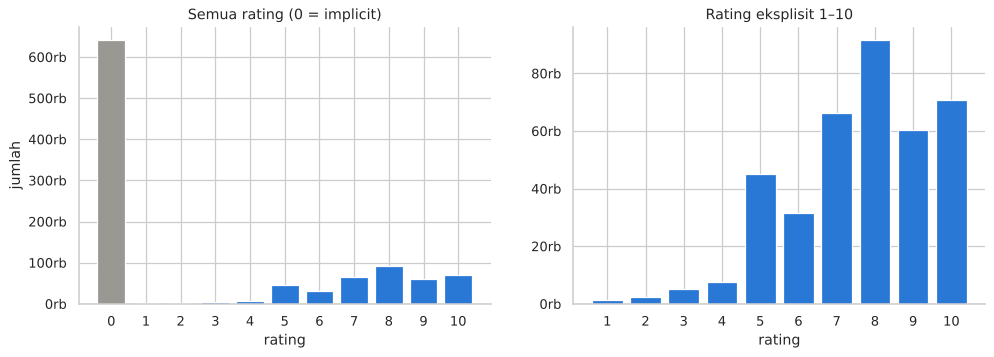

In [2]:
dist = ratings["rating"].round().astype(int).value_counts().sort_index()
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(dist.index, dist.values, color=[GRAY] + [BLUE] * 10, width=0.8)
ax[0].set(title="Semua rating (0 = implicit)", xlabel="rating", ylabel="jumlah", xticks=range(11))
d2 = dist.drop(0)
ax[1].bar(d2.index, d2.values, color=BLUE, width=0.8)
ax[1].set(title="Rating eksplisit 1–10", xlabel="rating", xticks=range(1, 11))
for a in ax: a.yaxis.set_major_formatter(lambda v, p: f"{v/1000:.0f}rb")
print(f"Porsi implicit (0): {(ratings['rating'] == 0).mean():.1%}")
print(f"Rata-rata rating eksplisit: {explicit['rating'].mean():.2f}  (sd = {explicit['rating'].std():.2f})")
print(f"Rating eksplisit >= 7: {(explicit['rating'] >= 7).mean():.1%}")

**Insight:**
- Mayoritas interaksi (±63%) adalah rating 0 / implicit.
- Rating eksplisit **condong ke kanan**: kebanyakan 7–10. Orang cenderung menilai buku yang mereka sukai (*selection bias*). Akibatnya rata-rata global saja sudah menjadi tebakan yang cukup baik, dan model perlu **bias user** (ada yang "pelit", ada yang "royal") serta **bias buku**.

Sebaran rata-rata per user cukup lebar -> perlu bias user (b_u) dalam model.


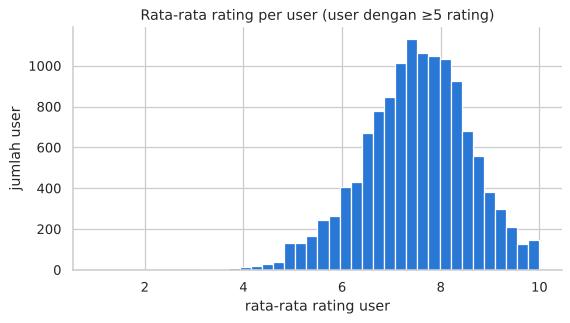

In [3]:
um = explicit.groupby("user_id")["rating"].agg(["mean", "size"])
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(um.loc[um["size"] >= 5, "mean"], bins=40, color=BLUE, edgecolor="white")
ax.set(title="Rata-rata rating per user (user dengan ≥5 rating)", xlabel="rata-rata rating user", ylabel="jumlah user")
print("Sebaran rata-rata per user cukup lebar -> perlu bias user (b_u) dalam model.")

## 2. Long-tail dan sparsity

User dengan hanya 1 rating eksplisit : 58%
Buku dengan hanya 1 rating eksplisit : 65%
Sparsity matriks eksplisit           : 99.99567%


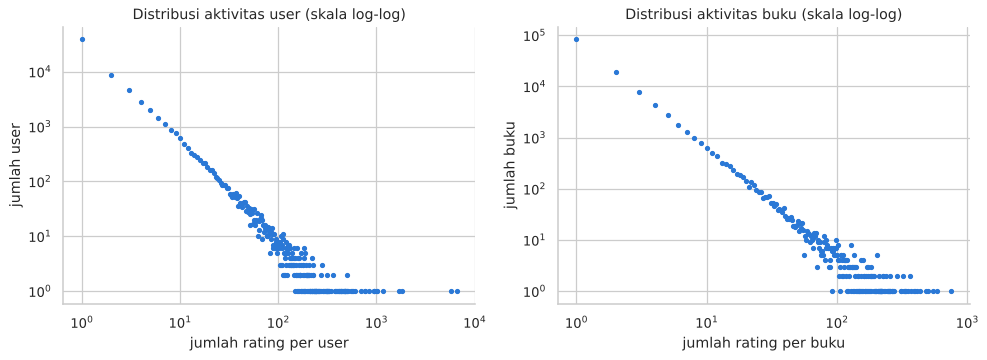

In [4]:
uc = explicit.groupby("user_id").size()
bc = explicit.groupby("book_id").size()
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, s, lab in [(ax[0], uc, "user"), (ax[1], bc, "buku")]:
    v = s.value_counts().sort_index()
    a.scatter(v.index, v.values, s=10, color=BLUE)
    a.set(xscale="log", yscale="log", xlabel=f"jumlah rating per {lab}", ylabel=f"jumlah {lab}",
          title=f"Distribusi aktivitas {lab} (skala log-log)")
print(f"User dengan hanya 1 rating eksplisit : {(uc == 1).mean():.0%}")
print(f"Buku dengan hanya 1 rating eksplisit : {(bc == 1).mean():.0%}")
print(f"Sparsity matriks eksplisit           : {1 - len(explicit) / (uc.size * bc.size):.5%}")

**Insight:** pola *power law* — sedikit user/buku punya sangat banyak rating, sebagian besar hanya 1. Matriks user × buku hanya terisi ±0,004%. Konsekuensinya:

- **Collaborative filtering** tidak bisa bekerja untuk user/buku yang hanya punya 1 rating → data perlu **difilter**.
- Bahkan setelah difilter, banyak user yang riwayatnya sedikit → **cold-start** → alasan memakai **hybrid switching**.

Berapa banyak data yang tersisa untuk berbagai ambang filter?

In [5]:
rows = []
for mb in [5, 10, 20, 50]:
    for mu in [3, 5, 10]:
        m = D.build_model_data(ratings, min_book=mb, min_user=mu)
        n_u, n_b = m["user_id"].nunique(), m["book_id"].nunique()
        rows.append({"min rating/buku": mb, "min rating/user": mu, "rating": len(m), "user": n_u,
                     "buku": n_b, "terisi (%)": round(100 * len(m) / (n_u * n_b), 3)})
pd.DataFrame(rows)

,min rating/buku,min rating/user,rating,user,buku,terisi (%)
0,5,3,173844,14264,13234,0.092
1,5,5,154877,8633,13199,0.136
2,5,10,125429,4083,13077,0.235
3,10,3,130559,11867,5658,0.194
4,10,5,114079,6979,5656,0.289
5,10,10,89691,3207,5636,0.496
6,20,3,92885,9525,2406,0.405
7,20,5,79018,5396,2405,0.609
8,20,10,60119,2447,2403,1.022
9,50,3,50917,6286,719,1.127


Dipilih **buku ≥ 10 rating** dan **user ≥ 3 rating**: data tetap besar (±130 ribu rating) dan masih memuat banyak user dengan riwayat sedikit. Ini penting agar kita bisa menguji perilaku model untuk user "dingin" vs "hangat". Minimal 3 rating per user agar setiap user punya data latih **dan** data uji.

## 3. Buku dan penulis dominan

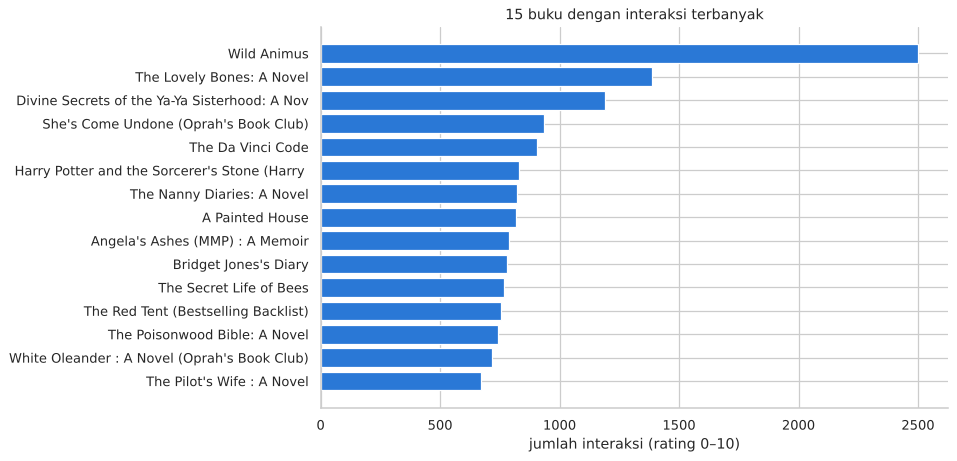

,title,author,n_interaksi,n_rating,rata2
book_id,,,,,
0971880107,Wild Animus,Rich Shapero,2502,581.0,4.39
0316666343,The Lovely Bones: A Novel,Alice Sebold,1388,752.0,8.18
0060928336,Divine Secrets of the Ya-Ya Sisterhood: A Novel,Rebecca Wells,1191,542.0,7.80
0671021001,She's Come Undone (Oprah's Book Club),Wally Lamb,934,434.0,7.66
0385504209,The Da Vinci Code,Dan Brown,906,500.0,8.43
059035342X,Harry Potter and the Sorcerer's Stone (Harry P...,J. K. Rowling,832,485.0,8.96
0312278586,The Nanny Diaries: A Novel,Emma McLaughlin,823,392.0,7.43
044023722X,A Painted House,John Grisham,819,363.0,7.38
0684872153,Angela's Ashes (MMP) : A Memoir,Frank McCourt,788,363.0,8.22


In [6]:
agg = (ratings.groupby("book_id").agg(n_interaksi=("rating", "size"))
       .join(explicit.groupby("book_id").agg(n_rating=("rating", "size"), rata2=("rating", "mean")))
       .join(books.set_index("book_id")[["title", "author"]]))
top = agg.sort_values("n_interaksi", ascending=False).head(15)
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(top["title"].str.slice(0, 45)[::-1], top["n_interaksi"][::-1], color=BLUE)
ax.set(title="15 buku dengan interaksi terbanyak", xlabel="jumlah interaksi (rating 0–10)")
top[["title", "author", "n_interaksi", "n_rating", "rata2"]].round(2).head(10)

Catatan menarik: **Wild Animus** adalah buku dengan interaksi terbanyak, tetapi rata-rata ratingnya hanya ±4,4 dan sebagian besar interaksinya rating 0. Buku ini dikenal banyak dibagikan gratis sebagai promosi oleh penulisnya. Ini contoh mengapa **jumlah interaksi ≠ disukai**, sehingga popularitas di proyek ini memakai *weighted rating*, bukan sekadar jumlah.

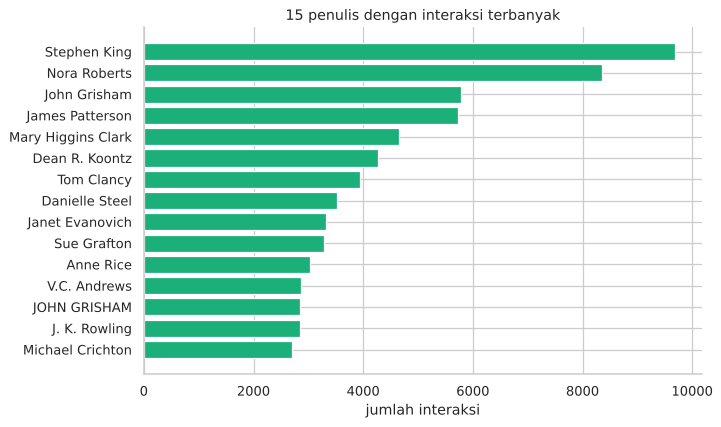

In [7]:
ta = ratings.merge(books[["book_id", "author"]], on="book_id").groupby("author").size().sort_values(ascending=False).head(15)
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(ta.index[::-1], ta.values[::-1], color=AQUA)
ax.set(title="15 penulis dengan interaksi terbanyak", xlabel="jumlah interaksi");

Seberapa "setia" pembaca pada penulis? Untuk tiap user, hitung proporsi bukunya yang ditulis oleh **penulis yang sama dengan buku lain di riwayatnya**.

In [8]:
m = D.build_model_data(ratings).merge(books[["book_id", "author"]], on="book_id")
per_user = m.groupby("user_id").agg(n=("book_id", "size"), n_author=("author", "nunique"))
per_user = per_user[per_user["n"] >= 5]
per_user["porsi_penulis_berulang"] = 1 - per_user["n_author"] / per_user["n"]
print(f"Median porsi buku dari penulis yang berulang (user ≥5 buku): {per_user['porsi_penulis_berulang'].median():.0%}")
print(f"User yang membaca ≥2 buku dari penulis yang sama            : {(per_user['n_author'] < per_user['n']).mean():.0%}")

Median porsi buku dari penulis yang berulang (user ≥5 buku): 11%
User yang membaca ≥2 buku dari penulis yang sama            : 61%


**Insight:** ±61% pembaca (dengan ≥5 buku) membaca lebih dari satu buku dari penulis yang sama (seri Harry Potter, Grisham, Patterson, Stephen King, …). Ini petunjuk bahwa **Content-Based** (yang memakai penulis sebagai fitur) akan cukup kuat, dan **association rules** akan banyak menemukan pola seri.

## 4. Profil user

Usia kosong pada user aktif: 42%


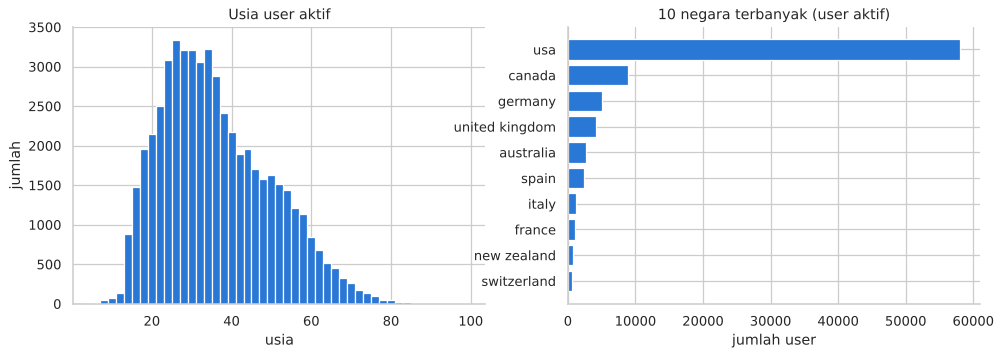

In [9]:
active_users = users[users["user_id"].isin(ratings["user_id"])]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(active_users["age"].dropna(), bins=range(5, 101, 2), color=BLUE, edgecolor="white")
ax[0].set(title="Usia user aktif", xlabel="usia", ylabel="jumlah")
cn = active_users["country"].value_counts().head(10)
ax[1].barh(cn.index[::-1], cn.values[::-1], color=BLUE)
ax[1].set(title="10 negara terbanyak (user aktif)", xlabel="jumlah user")
print(f"Usia kosong pada user aktif: {active_users['age'].isna().mean():.0%}")

**Insight:** usia kosong ±40% dan user didominasi Amerika Utara/Eropa. Data demografis kurang lengkap, sehingga **tidak dijadikan fitur utama** model. Usia/negara cukup untuk deskripsi dan bisa dipakai untuk *expert rules* (misalnya rekomendasi populer per negara) sebagai pengembangan.

## 5. Kesimpulan EDA → keputusan desain

| Temuan | Keputusan |
|---|---|
| 63% rating = 0 (implicit) | rating 0 hanya untuk association rules; prediksi rating pakai 1–10 |
| Rating menumpuk di 7–10, rata-rata per user bervariasi | model memakai bias user & bias buku (μ + b_u + b_i) |
| Matriks >99,99% kosong, long-tail ekstrem | filter buku ≥10 & user ≥3 rating |
| Banyak user dengan riwayat sedikit | **hybrid switching** berdasarkan jumlah riwayat |
| Pembaca setia pada penulis/seri | Content-Based memakai penulis; Apriori menemukan pola seri |
| Demografi tidak lengkap | tidak dipakai sebagai fitur model |

Lanjut ke **03_Pemodelan**.